!['https://media-cldnry.s-nbcnews.com/image/upload/t_fit-1000w,f_auto,q_auto:best/msnbc/Components/Photos/060324/060324_glacier_hlg_1p.jpg'](https://media-cldnry.s-nbcnews.com/image/upload/t_fit-1000w,f_auto,q_auto:best/msnbc/Components/Photos/060324/060324_glacier_hlg_1p.jpg)

## **Temperature at Many Glacier, MT**
For this activity we'll walk through how to access, open, and display temperature data from NOAA/NCEI using their automated programming interface (API).

Read more about the weather station at Many Glacier, MT: https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USS0013A27S/detail

Throughout the activity, you will be asked to replace text that is inside [square brackets]. When prompted, replace the text and remove the square brackets before running your code cell.

In [1]:
# STEP 0: Import python libraries

import pandas as pd  # working with datafames
import matplotlib.pyplot as plt # plotting
import numpy as np # working with arrays

In [14]:
# STEP 1: Build endpoint request from NOAA/NCEI for Many Glacier, MT

many_glacier_url = (
    "https://www.ncei.noaa.gov/access/services/data/v1"
    "?dataset=daily-summaries"
    "&stations=USS0013A27S"
    "&startDate=1976-09-30"
    "&endDate=2026-11-01"
    "&dataTypes=TOBS"
    "&includeStationName=true"
    "&includeStationLocation=1"
    "&units=standard")

many_glacier_url

'https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&stations=USS0013A27S&startDate=1976-09-30&endDate=2026-11-01&dataTypes=TOBS&includeStationName=true&includeStationLocation=1&units=standard'

In [15]:
# STEP 2: Open up data using pandas
many_glacier_df = pd.read_csv(many_glacier_url,
                              parse_dates=True,
                              index_col='DATE',
                              na_values=['NaN'])

# Clean up data (drop columns that aren't varying with time)
many_glacier_df = many_glacier_df['TOBS']
many_glacier_df

DATE
1976-09-30   NaN
1976-10-01   NaN
1976-10-02   NaN
1976-10-03   NaN
1976-10-04   NaN
              ..
2026-10-28   NaN
2026-10-29   NaN
2026-10-30   NaN
2026-10-31   NaN
2026-11-01   NaN
Name: TOBS, Length: 18295, dtype: float64

<Axes: xlabel='DATE'>

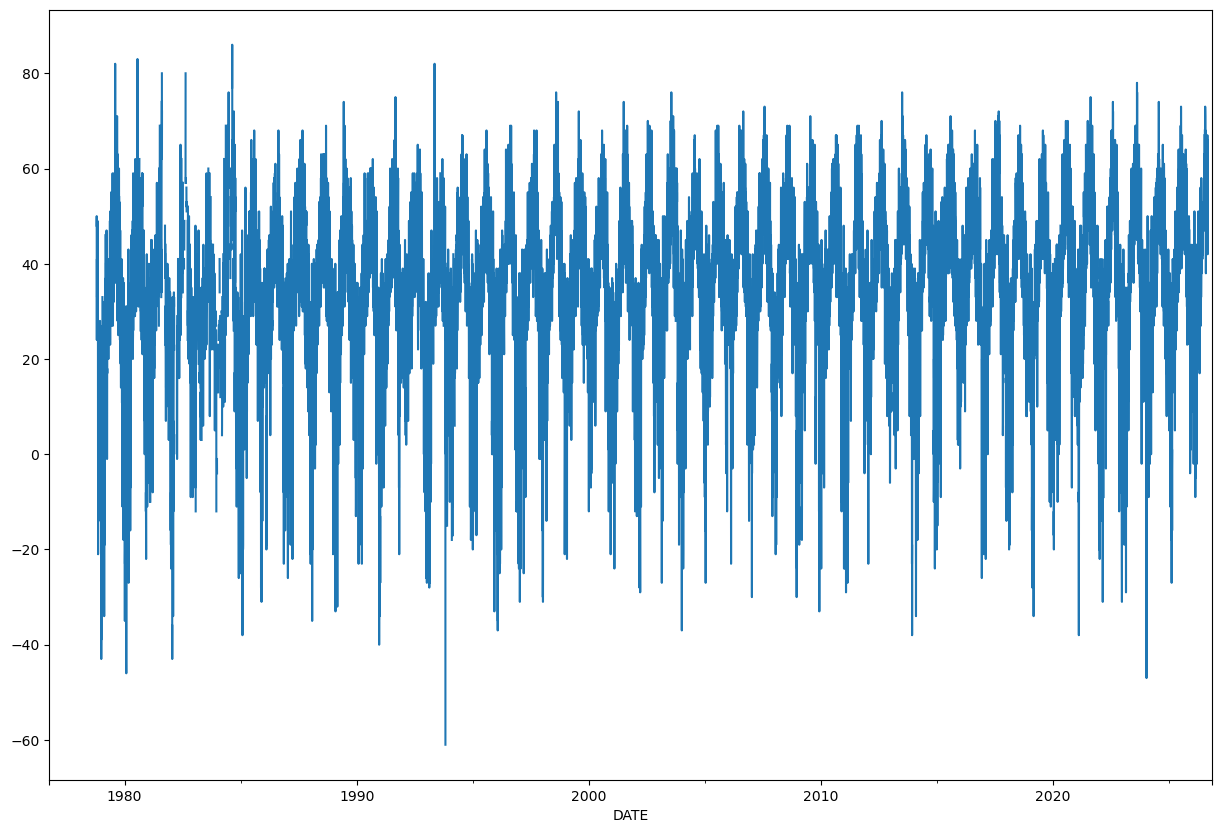

In [16]:
# STEP 3: Plot the data
many_glacier_df.plot(figsize=(15,10))

In [17]:
# STEP 4: Resample to look at annual mean
many_glacier_am = many_glacier_df.resample('YE').mean()
many_glacier_am

DATE
1976-12-31          NaN
1977-12-31          NaN
1978-12-31    16.958333
1979-12-31    30.415473
1980-12-31    30.069364
1981-12-31    29.729008
1982-12-31    26.740741
1983-12-31    28.765258
1984-12-31    30.477912
1985-12-31    28.224658
1986-12-31    33.024658
1987-12-31    34.741047
1988-12-31    33.284153
1989-12-31    31.958217
1990-12-31    31.986301
1991-12-31    33.183562
1992-12-31    33.980822
1993-12-31    31.541547
1994-12-31    34.595989
1995-12-31    33.128767
1996-12-31    30.441096
1997-12-31    33.692308
1998-12-31    35.180822
1999-12-31    35.639118
2000-12-31    33.763736
2001-12-31    35.221918
2002-12-31    33.010959
2003-12-31    36.220994
2004-12-31    35.688525
2005-12-31    36.268493
2006-12-31    36.783562
2007-12-31    37.038356
2008-12-31    35.016393
2009-12-31    33.720548
2010-12-31    35.819178
2011-12-31    34.898630
2012-12-31    36.349727
2013-12-31    36.487671
2014-12-31    35.528767
2015-12-31    38.482192
2016-12-31    37.942623
2017-12-31 

In [18]:
# STEP 5: Subset the data to look at 1980-2020
many_glacier_subset = many_glacier_am["1980":"2020"]
many_glacier_subset

DATE
1980-12-31    30.069364
1981-12-31    29.729008
1982-12-31    26.740741
1983-12-31    28.765258
1984-12-31    30.477912
1985-12-31    28.224658
1986-12-31    33.024658
1987-12-31    34.741047
1988-12-31    33.284153
1989-12-31    31.958217
1990-12-31    31.986301
1991-12-31    33.183562
1992-12-31    33.980822
1993-12-31    31.541547
1994-12-31    34.595989
1995-12-31    33.128767
1996-12-31    30.441096
1997-12-31    33.692308
1998-12-31    35.180822
1999-12-31    35.639118
2000-12-31    33.763736
2001-12-31    35.221918
2002-12-31    33.010959
2003-12-31    36.220994
2004-12-31    35.688525
2005-12-31    36.268493
2006-12-31    36.783562
2007-12-31    37.038356
2008-12-31    35.016393
2009-12-31    33.720548
2010-12-31    35.819178
2011-12-31    34.898630
2012-12-31    36.349727
2013-12-31    36.487671
2014-12-31    35.528767
2015-12-31    38.482192
2016-12-31    37.942623
2017-12-31    35.479452
2018-12-31    35.460274
2019-12-31    33.263158
2020-12-31    36.533149
Freq: YE-DE

<Axes: title={'center': 'Avg Annual Temp - Many Glacier, MT'}, xlabel='DATE', ylabel='Temperature (F)'>

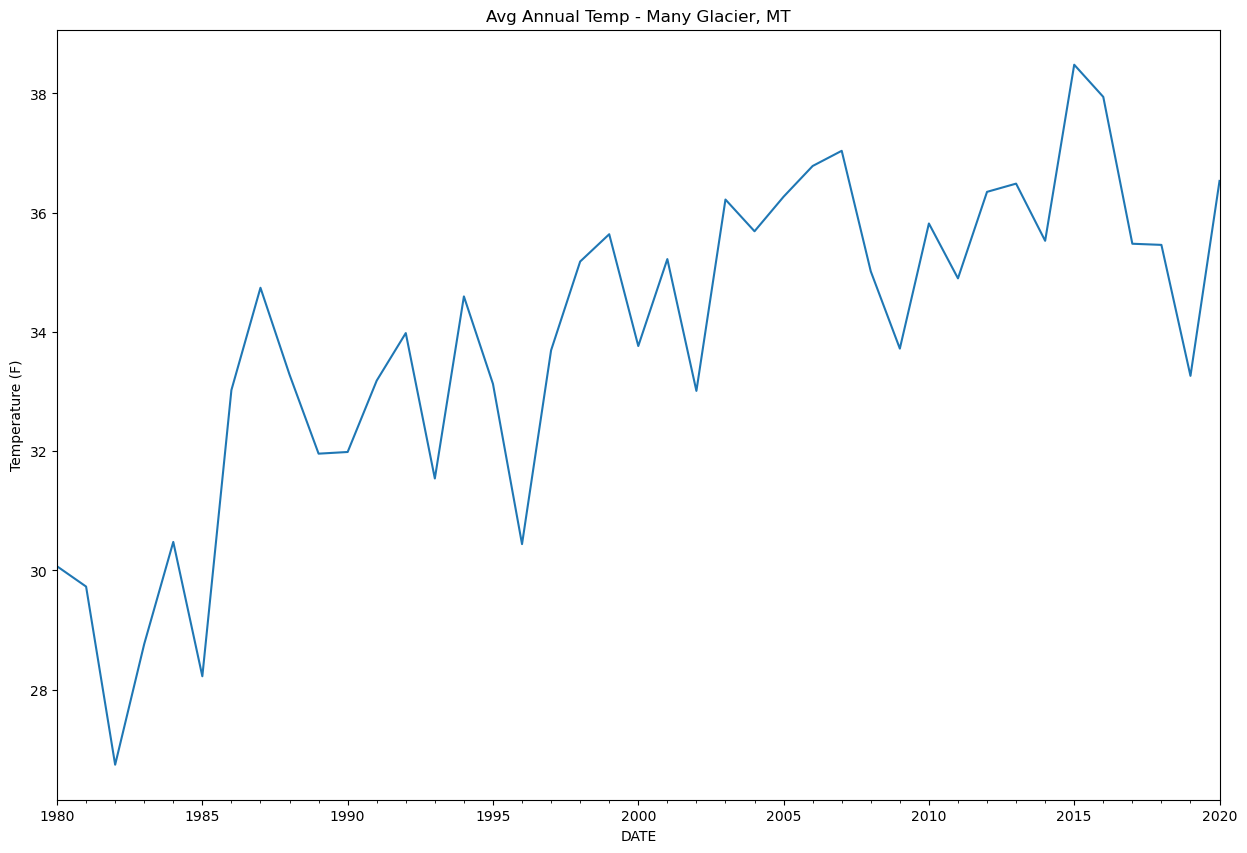

In [21]:
# STEP 6: Plot 1980-2020 data
many_glacier_subset.plot(y='TOBS', figsize=(15,10),
                            ylabel='Temperature (F)',
                            title='Avg Annual Temp - Many Glacier, MT')

In [22]:
# STEP 7: Resetting the index
many_glacier_subset = many_glacier_subset.reset_index()
many_glacier_subset

,DATE,TOBS
0,1980-12-31,30.069364
1,1981-12-31,29.729008
2,1982-12-31,26.740741
3,1983-12-31,28.765258
4,1984-12-31,30.477912
5,1985-12-31,28.224658
6,1986-12-31,33.024658
7,1987-12-31,34.741047
8,1988-12-31,33.284153
9,1989-12-31,31.958217


In [23]:
# STEP 8: Remove year from DATE column and add as new variable
many_glacier_subset['YEAR'] = many_glacier_subset['DATE'].dt.year
many_glacier_subset

,DATE,TOBS,YEAR
0,1980-12-31,30.069364,1980
1,1981-12-31,29.729008,1981
2,1982-12-31,26.740741,1982
3,1983-12-31,28.765258,1983
4,1984-12-31,30.477912,1984
5,1985-12-31,28.224658,1985
6,1986-12-31,33.024658,1986
7,1987-12-31,34.741047,1987
8,1988-12-31,33.284153,1988
9,1989-12-31,31.958217,1989


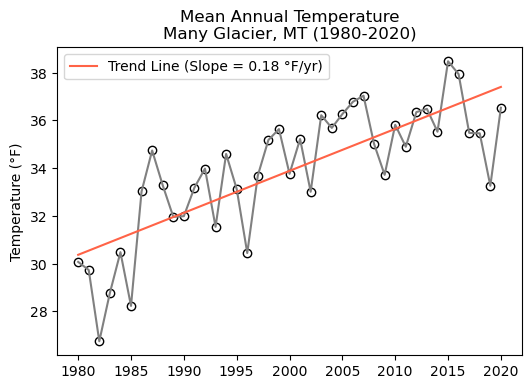

In [24]:
# STEP 9: Plotting with a trendline (OPTIONAL IF TIME ALLOWS)
# Define our figure and axis objects
fig, ax = plt.subplots(figsize=(6,4))

# Compute linear regression
x = many_glacier_subset['YEAR']
y = many_glacier_subset['TOBS']

# Compute the slope (m) and intercept (b) of the line y = mx + b
m, b = np.polyfit(x, y, 1)

# Define degree symbol
degree_symbol = '\u00B0'

# Plot TOBS vs. YEAR as scatter plot
ax.scatter(x, y, color='white', edgecolor='black')

# Plot line graph
ax.plot(many_glacier_subset['YEAR'],
        many_glacier_subset['TOBS'],
        color='grey')

# Plot trend line
ax.plot(x, m*x + b, color='tomato', label=f'Trend Line (Slope = {m:.2f} {degree_symbol}F/yr)')

# Add legend
ax.legend()

# Add title and axis label
ax.set(title="Mean Annual Temperature\nMany Glacier, MT (1980-2020)",
       ylabel="Temperature (\u00B0F)")

plt.show()

***

# **NOW IT'S YOUR TURN!**
Try to recreate this workflow for another weather station of your choice. You can create new code cells below to get started (**HINT**: hover your mouse over the center of the screen below this cell and select the `+ Code` button). You can try copying and pasting the code you wrote for Many Glacier, MT and making changes. Be careful with copy/paste and double-check for errors before running your code.

Check the NOAA NCEI Climate Data Online **Search Tool** for a site/station that is interesting to you: https://www.ncei.noaa.gov/cdo-web/


Have fun!